1. Task 2 :- Exploratory Data Analysis (Week 2)
2. Dataset :- Hotel Booking Dataset

## 1. Importing Libraries

In this section, we import the Python libraries required to perform exploratory data analysis.

- Pandas: Used for loading, manipulating, cleaning, and analysing structured datasets.
- NumPy: Used for numerical calculations and mathematical operations.
- Matplotlib: Used to create different types of data visualizations.
- Seaborn: Used to create statistical visualizations such as histograms, box plots, and correlation heatmaps.
- Warnings: Used to control unnecessary warning messages during analysis.

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

## 2. Loading the Dataset

In this section, we load the Hotel Booking Demand dataset into a Pandas DataFrame.

The dataset is stored in CSV format. We use the `read_csv()` function to import the data.

A DataFrame allows us to access, inspect, manipulate, and analyse the dataset using Pandas.

The raw dataset will be preserved separately so that the original data remains unchanged during our analysis.

In [51]:
df = pd.read_csv("raw_dataset/hotel_bookings.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Initial Data Inspection

Before performing exploratory data analysis, it is important to understand the structure and contents of the dataset.

In this section, we will inspect the dataset dimensions, view sample records, examine column names, and identify numerical and categorical variables.

This initial inspection helps us understand what information is available and which analysis techniques can be applied to different columns.

In [52]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Display last five records
print("\nLast Five Records:")
display(df.tail())

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical Columns:", numerical_columns)
print("\nCategorical Columns:", categorical_columns)

Dataset Shape: (119390, 32)

First Five Records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Last Five Records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07



Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int6

### 3.1 Initial Data Inspection – Observations

The initial inspection of the Hotel Booking Demand dataset reveals the following:

1. Dataset Dimensions: The dataset contains 119,390 rows and 32 columns, indicating a large collection of hotel booking records.

2. Numerical Variables: The dataset contains 20 numerical columns, including lead time, arrival year, number of guests, booking changes, and average daily rate (ADR).

3. Categorical Variables: The dataset contains 12 columns identified as categorical, including hotel type, meal plan, market segment, customer type, and reservation status.

4. Data Types: Most numerical variables have integer or floating-point data types, while categorical variables are stored as strings.

5. Potential Data Quality Issues: The initial inspection shows missing values in some columns, including children, country, agent, and company. These will be investigated in the data quality assessment.

6. Date Information: The reservation_status_date column is currently stored as a string and may need conversion into datetime format for date-based analysis.


## 4. Data Quality Assessment

Data quality assessment is an important step in exploratory data analysis. It helps identify issues that may affect the accuracy and reliability of our analysis.

In [53]:
# Calculate missing values for each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print("Columns Containing Missing Values:")
display(missing_summary)

# Calculate total missing values in the dataset
print("Total Missing Values:", df.isnull().sum().sum())

Columns Containing Missing Values:


,Missing Values,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


Total Missing Values: 129425


In [54]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Total Duplicate Records:", duplicate_count)
print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

# Display duplicate records if available
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate records found.")

Total Duplicate Records: 31994
Duplicate Percentage: 26.8 %


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


## 5. Missing Value Handling

Missing values can affect statistical calculations and data analysis. Therefore, it is important to handle them before proceeding with exploratory data analysis.

Based on the initial data quality assessment, missing values were identified in four columns: `company`, `agent`, `country`, and `children`.

The following strategies will be applied:

- Company: Replace missing values with 0.
- Agent: Replace missing values with 0.
- Country: Replace missing values with "Unknown".
- Children: Replace missing values with 0.

In [55]:
# Create a copy of the original dataset
df_clean = df.copy()

# Replace missing values
df_clean["company"] = df_clean["company"].fillna(0)
df_clean["agent"] = df_clean["agent"].fillna(0)
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["children"] = df_clean["children"].fillna(0)

print("Missing values handled successfully!")

Missing values handled successfully!


In [56]:
# Check missing values after treatment
remaining_missing = df_clean.isnull().sum()

print("Missing Values After Cleaning:")
print(remaining_missing[remaining_missing > 0])

print("\nTotal Remaining Missing Values:",
      df_clean.isnull().sum().sum())

Missing Values After Cleaning:
Series([], dtype: int64)

Total Remaining Missing Values: 0


## 5.1 Observations

Missing values were handled successfully in the company, agent, country, and children columns using the selected replacement strategies.

Missing company and agent identifiers were replaced with 0.

Missing country values were replaced with "Unknown".

Missing children values were replaced with 0.

After applying these treatments, the dataset was checked again to verify the remaining missing values.

## 6. Duplicate Records Handling

Duplicate records are rows that contain identical values across all columns in a dataset.

Duplicates can affect statistical calculations, frequency distributions, and analytical results. Therefore, identifying and handling duplicate records is an important part of data cleaning.

## 6.1 Identifying Duplicate Records

Before removing duplicate records, we need to identify how many exact duplicate rows are present in the dataset.

The Pandas duplicated() method identifies rows that have already appeared earlier in the dataset.

By default, the first occurrence of a record is considered unique, while subsequent identical occurrences are marked as duplicates.

In [57]:
# Identify duplicate records
duplicate_count = df_clean.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df_clean)) * 100

print("Total Duplicate Records:", duplicate_count)
print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

# Display sample duplicate records
duplicate_records = df_clean[df_clean.duplicated(keep=False)]

display(duplicate_records.head(10))

Total Duplicate Records: 31994
Duplicate Percentage: 26.8 %


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08


## 6.2 Removing Duplicate Records

After identifying duplicate records, we will remove exact duplicate rows using the Pandas drop_duplicates() method.

The keep='first' parameter retains the first occurrence of each identical record and removes subsequent occurrences.

This approach eliminates repeated rows while retaining one representative record from each duplicate group.

In [58]:
# Store the dataset shape before removing duplicates
rows_before = df_clean.shape[0]

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates(keep="first")

# Store the dataset shape after removing duplicates
rows_after = df_clean.shape[0]

# Calculate removed records
removed_records = rows_before - rows_after

print("Rows Before Duplicate Removal:", rows_before)
print("Rows After Duplicate Removal:", rows_after)
print("Total Records Removed:", removed_records)

Rows Before Duplicate Removal: 119390
Rows After Duplicate Removal: 87396
Total Records Removed: 31994


In [59]:
# Check remaining duplicates
remaining_duplicates = df_clean.duplicated().sum()

print("Remaining Duplicate Records:", remaining_duplicates)
print("Final Dataset Shape:", df_clean.shape)

if remaining_duplicates == 0:
    print("All exact duplicate records have been removed.")

Remaining Duplicate Records: 0
Final Dataset Shape: (87396, 32)
All exact duplicate records have been removed.


The dataset initially contained 31,994 exact duplicate records. These records were removed using `drop_duplicates(keep="first")`, retaining one copy of each identical record.

- Original records: 119,390
- Duplicate records removed: 31,994
- Records after cleaning: 87,396
- Remaining exact duplicates: 0

The dataset now contains 87,396 rows and 32 columns. No columns were removed. Only exact duplicate rows were eliminated.

### 7. Save the Cleaned Dataset

After handling missing values and removing exact duplicate records, save the cleaned dataset in the `data/cleaned` folder. This file will be used for the upcoming exploratory data analysis.

In [60]:
df_clean.to_csv("cleaned_dataset/hotel_bookings_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Dataset Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final Dataset Shape: (87396, 32)


### 8 Descriptive Statistics of Numerical Columns

Descriptive statistics provide a statistical summary of numerical variables. Measures such as mean, median, standard deviation, minimum, maximum and quartiles help us understand the central tendency, spread and distribution of the data.

Identifier columns such as `agent` and `company` will be excluded from the main numerical summary because their values represent IDs rather than measurable quantities.

In [61]:
numerical_features = df_clean.select_dtypes(include=np.number).columns.tolist()

# Exclude identifier columns
numerical_features = [
    col for col in numerical_features
    if col not in ["agent", "company"]
]

numerical_summary = df_clean[numerical_features].describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
is_canceled,87396.0,0.274898,0.446466,0.00,0.0,0.0,1.0,1.0
lead_time,87396.0,79.891368,86.052325,0.00,11.0,49.0,125.0,737.0
arrival_date_year,87396.0,2016.210296,0.686102,2015.00,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87396.0,26.838334,13.674572,1.00,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87396.0,15.815541,8.835146,1.00,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87396.0,1.005263,1.031921,0.00,0.0,1.0,2.0,19.0
stays_in_week_nights,87396.0,2.625395,2.053584,0.00,1.0,2.0,4.0,50.0
adults,87396.0,1.875795,0.626500,0.00,2.0,2.0,2.0,55.0
children,87396.0,0.138633,0.455871,0.00,0.0,0.0,0.0,10.0
babies,87396.0,0.010824,0.113597,0.00,0.0,0.0,0.0,10.0


### Interpretation of Numerical Descriptive Statistics

1. Booking cancellations: The mean of `is_canceled` is approximately 0.275, indicating that around 27.49% of bookings in the cleaned dataset were canceled.

2. Lead time: The average lead time is approximately 79.89 days, while the median is 49 days. This indicates that the distribution is right-skewed, with some bookings made much earlier than others.

3. Stay duration: Guests stay an average of approximately 1 weekend night and 2.63 weekday nights. The median weekday stay is 2 nights.

4. Guest composition: The average number of adults is approximately 1.88 per booking. The median values for children and babies are both zero, suggesting that most bookings do not include children or babies.

5. Repeated guests: The mean of `is_repeated_guest` is approximately 0.039, suggesting that around 3.91% of bookings belong to repeated guests.

6. Special requests: The average number of special requests is approximately 0.70 per booking, while the median is zero.

7. Potential outliers: Some variables have unusually high maximum values, such as `lead_time` (737), `adults` (55), `adr` (5400), and `days_in_waiting_list` (391). The negative minimum ADR value (-6.38) also requires investigation.

These unusual values will be examined further during outlier analysis rather than removed without investigation.

### 8.1 Descriptive Statistics of Categorical Columns

Categorical descriptive statistics help us understand the different categories present in the dataset.

We will examine:
- Count: Total non-null records
- Unique: Number of distinct categories
- Top: Most frequently occurring category
- Freq: Frequency of the most common category

In [62]:
categorical_features = df_clean.select_dtypes(include="object").columns.tolist()

categorical_summary = df_clean[categorical_features].describe().T

display(categorical_summary)

,count,unique,top,freq
hotel,87396,2,City Hotel,53428
arrival_date_month,87396,12,August,11257
meal,87396,5,BB,67978
country,87396,178,PRT,27453
market_segment,87396,8,Online TA,51618
distribution_channel,87396,5,TA/TO,69141
reserved_room_type,87396,10,A,56552
assigned_room_type,87396,12,A,46313
deposit_type,87396,3,No Deposit,86251
customer_type,87396,4,Transient,71986


### Interpretation of Categorical Descriptive Statistics

1. Hotel type: City Hotel is the most frequent hotel type, with 53,428 records out of 87,396.

2. Arrival month: August is the most frequently recorded arrival month, with 11,257 bookings.

3. Meal plan: BB is the most common meal plan, appearing in 67,978 records.

4. Country: PRT (Portugal) is the most frequently recorded country, with 27,453 records.

5. Market segment: Online TA (Online Travel Agents) is the most common market segment, with 51,618 records.

6. Distribution channel: TA/TO (Travel Agents/Tour Operators) is the most frequent distribution channel, with 69,141 records.

7. Room type: Room type A is the most frequently reserved room type, with 56,552 records. It is also the most frequently assigned room type, with 46,313 records.

8. Deposit type: No Deposit is the dominant deposit category, appearing in 86,251 records.

9. Customer type: Transient customers are the most frequent customer type, with 71,986 records.

10. Reservation status: Check-Out is the most common reservation status, with 63,371 records.

Overall, the dataset contains a strong concentration of City Hotel bookings, online travel-agent bookings, and transient customers.

## 9. Data Visualization – Univariate Analysis

### 9.1 Distribution of Numerical Features

Histograms show the frequency distribution of numerical variables, while Kernel Density Estimation (KDE) curves provide a smoothed representation of the distribution.

We will visualize selected numerical features, including lead time, average daily rate (ADR), stay duration, waiting-list days, and special requests. These variables can help us understand booking patterns and guest behavior.

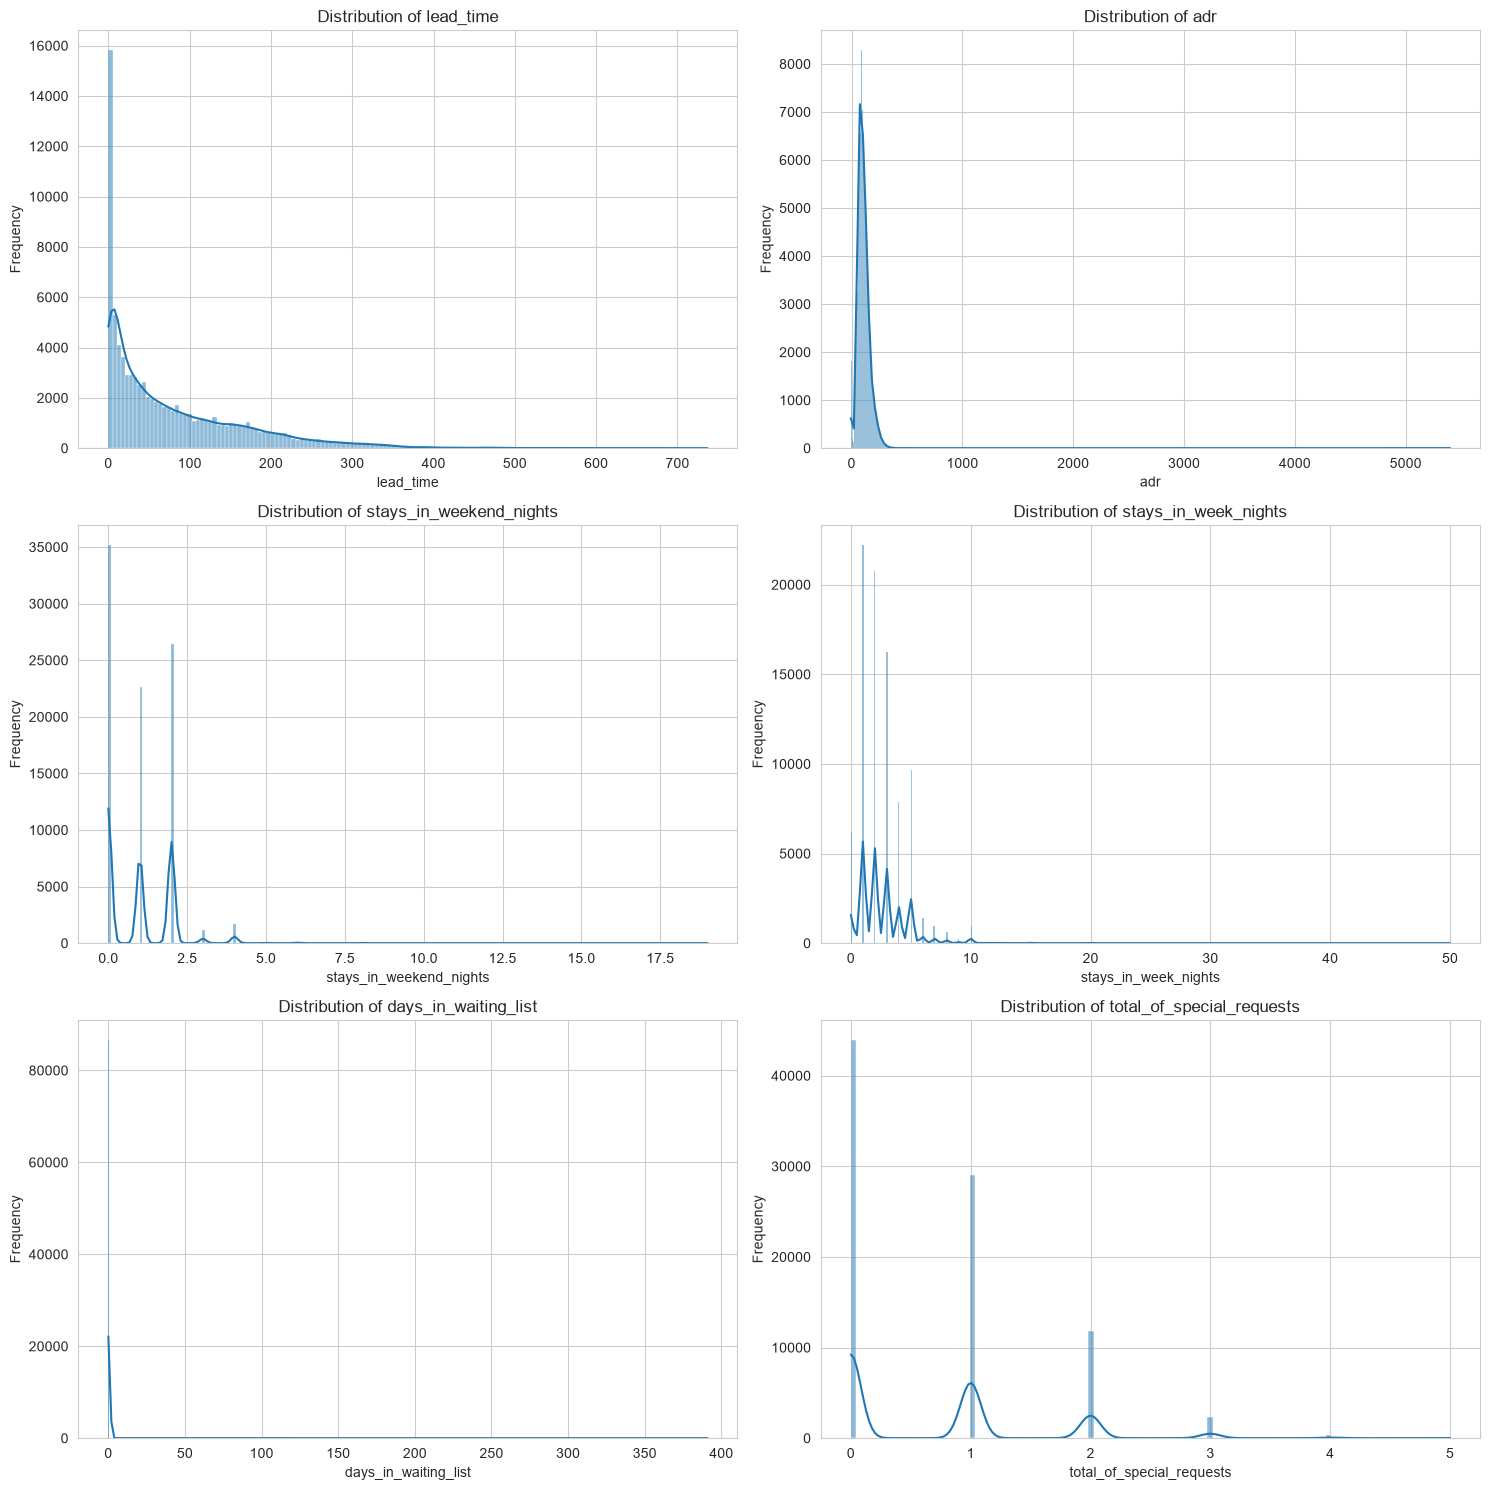

In [63]:
import os

features_to_plot = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "days_in_waiting_list",
    "total_of_special_requests"
]

os.makedirs("outputs/charts", exist_ok=True)

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("outputs/charts/numerical_distributions.png", dpi=300)
plt.show()

## 10. Correlation Analysis

Correlation analysis helps us understand the strength and direction
of relationships between numerical variables.

We use the Pearson correlation coefficient, which ranges from -1 to +1.

In [64]:

# Select numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

# Remove identifier columns because IDs are not meaningful numerical measurements
numeric_cols = [
    col for col in numeric_cols
    if col not in ["agent", "company"]
]

# Calculate correlation matrix
correlation_matrix = df_clean[numeric_cols].corr(method="pearson")

# Display correlation matrix
correlation_matrix


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
is_canceled,1.000000,0.184806,0.088030,0.001443,0.005328,0.060191,0.082928,0.081816,0.067369,-0.020543,-0.089643,0.051468,-0.052154,-0.093644,0.004464,0.127986,-0.184206,-0.120545
lead_time,0.184806,1.000000,0.139135,0.101150,0.009866,0.235145,0.310129,0.140493,0.028650,-0.003614,-0.147003,0.005375,-0.078931,0.077028,0.132152,0.023564,-0.086541,0.034240
arrival_date_year,0.088030,0.139135,1.000000,-0.514228,-0.010023,0.005144,0.003645,0.038619,0.041158,-0.023334,0.024343,-0.054212,0.027256,0.008604,-0.027939,0.176088,-0.039807,0.064268
arrival_date_week_number,0.001443,0.101150,-0.514228,1.000000,0.093594,0.026868,0.027801,0.024362,0.013450,0.014260,-0.036860,0.007199,-0.020819,0.011902,0.013843,0.098279,0.008946,0.046599
arrival_date_day_of_month,0.005328,0.009866,-0.010023,0.093594,1.000000,-0.017803,-0.028190,-0.001125,0.015821,-0.000393,-0.004178,-0.008538,0.000152,0.006307,0.006588,0.022591,0.009167,-0.001651
stays_in_weekend_nights,0.060191,0.235145,0.005144,0.026868,-0.017803,1.000000,0.555552,0.088284,0.028561,0.013668,-0.106948,-0.020636,-0.056653,0.050316,-0.031680,0.038972,-0.042920,0.032396
stays_in_week_nights,0.082928,0.310129,0.003645,0.027801,-0.028190,0.555552,1.000000,0.095577,0.030479,0.016009,-0.113543,-0.018781,-0.058503,0.085044,0.001905,0.053298,-0.044303,0.037823
adults,0.081816,0.140493,0.038619,0.024362,-0.001125,0.088284,0.095577,1.000000,0.023712,0.016640,-0.171714,-0.042097,-0.120914,-0.048061,-0.015740,0.248999,0.007802,0.112772
children,0.067369,0.028650,0.041158,0.013450,0.015821,0.028561,0.030479,0.023712,1.000000,0.017423,-0.045651,-0.019208,-0.029423,0.031313,-0.020419,0.326293,0.036332,0.044596
babies,-0.020543,-0.003614,-0.023334,0.014260,-0.000393,0.013668,0.016009,0.016640,0.017423,1.000000,-0.012977,-0.005395,-0.009193,0.081035,-0.006840,0.023446,0.030885,0.094820


### Correlation Heatmap

A correlation heatmap provides a visual representation of relationships
between numerical variables.

Positive correlations indicate variables moving in the same direction,
while negative correlations indicate variables moving in opposite directions.

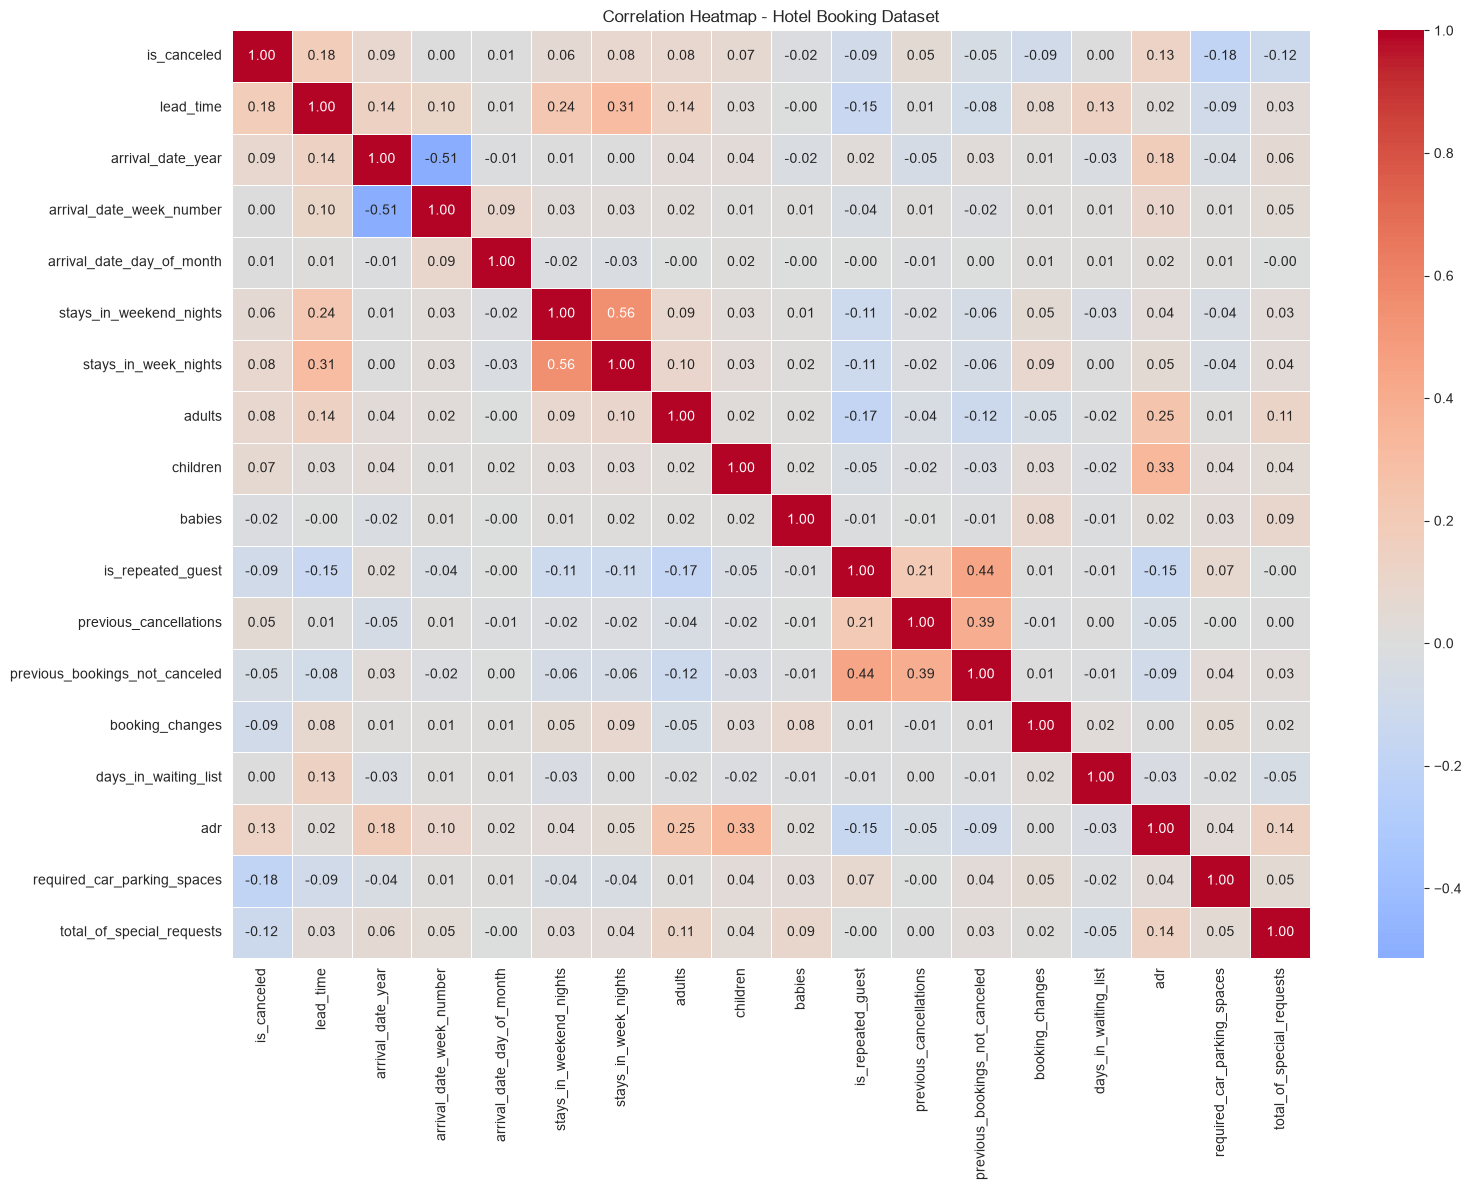

In [65]:

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap - Hotel Booking Dataset")
plt.tight_layout()

plt.savefig(
    "outputs/charts/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [66]:

# Convert correlation matrix into pairs
correlation_pairs = correlation_matrix.unstack()

# Remove self-correlations and duplicate pairs
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) <
    correlation_pairs.index.get_level_values(1)
]

# Sort by absolute correlation
strongest_correlations = correlation_pairs.reindex(
    correlation_pairs.abs().sort_values(ascending=False).index
)

# Display top 10 relationships
strongest_correlations.head(10)


stays_in_week_nights            stays_in_weekend_nights           0.555552
arrival_date_week_number        arrival_date_year                -0.514228
is_repeated_guest               previous_bookings_not_canceled    0.441456
previous_bookings_not_canceled  previous_cancellations            0.392064
adr                             children                          0.326293
lead_time                       stays_in_week_nights              0.310129
adr                             adults                            0.248999
lead_time                       stays_in_weekend_nights           0.235145
is_repeated_guest               previous_cancellations            0.206374
is_canceled                     lead_time                         0.184806
dtype: float64

### Interpretation

1. The strongest positive correlation was observed between `stays_in_week_nights` and `stays_in_weekend_nights` (0.56). This indicates that guests staying longer during weekdays also tend to stay longer during weekends.

2. The strongest negative correlation was observed between `arrival_date_week_number` and `arrival_date_year` (-0.51). This indicates a moderate negative relationship between these variables, although it may be influenced by the distribution of booking dates across different years.

3. A moderate positive correlation (0.44) was observed between `is_repeated_guest` and `previous_bookings_not_canceled`, suggesting that repeat guests tend to have a history of bookings that were not canceled.

4. A weak positive correlation (0.18) was observed between `is_canceled` and `lead_time`, suggesting that bookings made further in advance have a slightly higher tendency to be canceled.

5. Most variable pairs do not show very strong linear relationships, indicating that hotel booking patterns are influenced by multiple factors.



## 11. Box Plot Analysis

Box plots help visualize the distribution of numerical variables
and identify potential outliers.

In this analysis, we compare booking characteristics between
City Hotel and Resort Hotel to understand differences in
booking patterns and identify unusual observations.


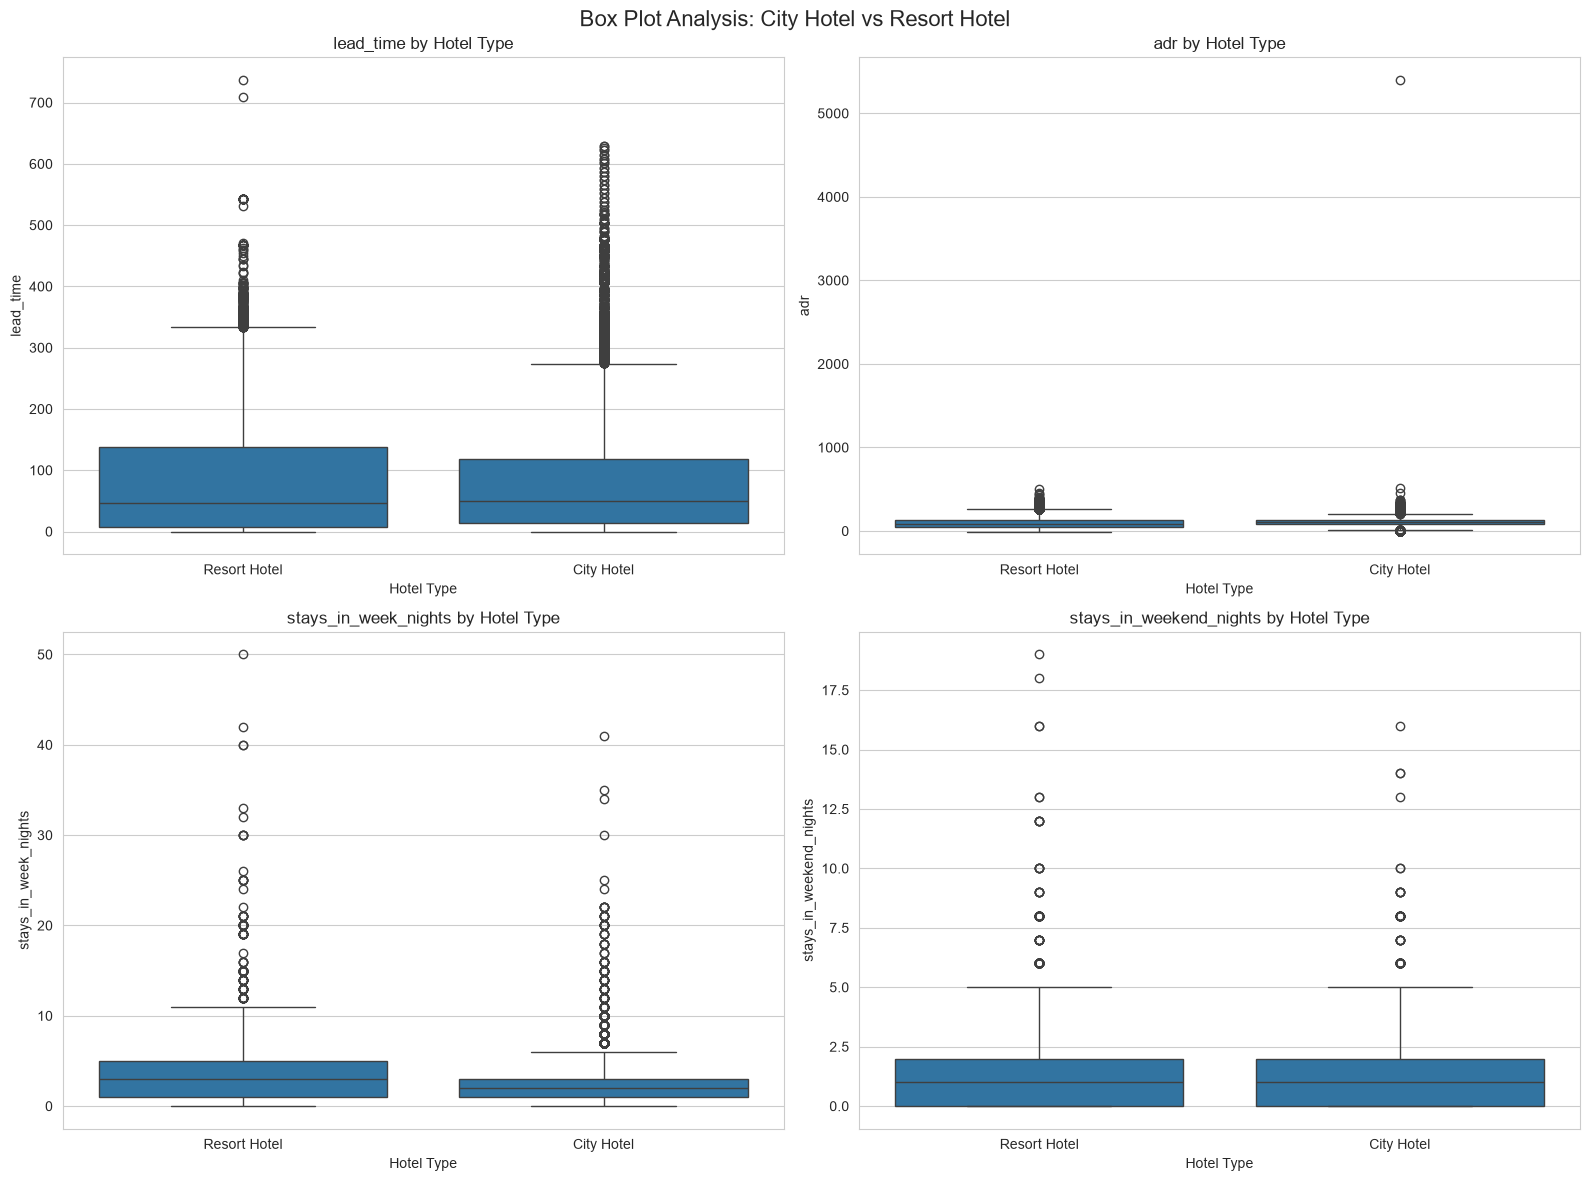

In [67]:

# Features to compare across hotel types
features = [
    "lead_time",
    "adr",
    "stays_in_week_nights",
    "stays_in_weekend_nights"
]

# Create output directory
os.makedirs("../outputs/charts", exist_ok=True)

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df_clean,
        x="hotel",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Hotel Type")
    ax.set_xlabel("Hotel Type")
    ax.set_ylabel(feature)

plt.suptitle(
    "Box Plot Analysis: City Hotel vs Resort Hotel",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/boxplots_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [68]:

outlier_results = []

for feature in features:

    for hotel_type in df_clean["hotel"].dropna().unique():

        data = df_clean.loc[
            df_clean["hotel"] == hotel_type,
            feature
        ].dropna()

        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outliers = data[
            (data < lower_limit) |
            (data > upper_limit)
        ]

        outlier_results.append({
            "Feature": feature,
            "Hotel": hotel_type,
            "Outlier Count": len(outliers),
            "Outlier Percentage": round(
                len(outliers) / len(data) * 100, 2
            )
        })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary


,Feature,Hotel,Outlier Count,Outlier Percentage
0,lead_time,Resort Hotel,606,1.78
1,lead_time,City Hotel,1697,3.18
2,adr,Resort Hotel,753,2.22
3,adr,City Hotel,2490,4.66
4,stays_in_week_nights,Resort Hotel,179,0.53
5,stays_in_week_nights,City Hotel,687,1.29
6,stays_in_weekend_nights,Resort Hotel,140,0.41
7,stays_in_weekend_nights,City Hotel,80,0.15


### Interpretation

1. The box plots show differences in the distribution of booking
   characteristics between City Hotel and Resort Hotel.

2. The median values indicate the typical booking characteristics
   for each hotel type.

3. Potential outliers were identified using the IQR method.
   These values represent observations outside the expected range.

4. Outlier percentages help identify which numerical features
   contain more unusual observations.

5. Outliers will not be removed automatically because they may
   represent genuine booking behavior.

In [69]:

# Investigate unusually high ADR values
df_clean.nlargest(
    10, "adr"
)[["hotel", "adr", "adults", "children", "babies"]]


,hotel,adr,adults,children,babies
48515,City Hotel,5400.00,2,0.0,0
111403,City Hotel,510.00,1,0.0,0
15083,Resort Hotel,508.00,2,0.0,0
103912,City Hotel,451.50,2,2.0,0
13142,Resort Hotel,450.00,2,0.0,0
13391,Resort Hotel,437.00,2,2.0,0
39155,Resort Hotel,426.25,2,2.0,0
39568,Resort Hotel,402.00,3,1.0,0
39118,Resort Hotel,397.38,3,2.0,0
13323,Resort Hotel,392.00,2,1.0,0


In [70]:

# Inspect the booking with the highest ADR
df_clean.loc[
    df_clean["adr"].idxmax()
].to_frame()


,48515
hotel,City Hotel
is_canceled,1
lead_time,35
arrival_date_year,2016
arrival_date_month,March
arrival_date_week_number,13
arrival_date_day_of_month,25
stays_in_weekend_nights,0
stays_in_week_nights,1
adults,2


### Additional Outlier Investigation – ADR

During the investigation of the highest ADR values, an unusually high ADR of 5400 was identified in a City Hotel booking.

The next highest values were considerably lower, indicating that the maximum value requires further investigation.

The record was not removed automatically because extreme values may represent genuine booking observations. Additional booking details will be examined to determine whether the value is valid or a potential data-quality issue.

### ADR Outlier Investigation – Findings

An unusually high ADR value of 5400 was identified in a City Hotel booking.

Further investigation revealed that the booking involved two adults staying for one weekday night. The reservation was canceled before the scheduled arrival date.

This observation is significantly higher than other ADR values in the dataset and may represent a potential data-quality anomaly.

However, the record was retained because there is insufficient evidence to confirm that it is incorrect.



## 12. Time-Series Analysis

Time-series analysis helps identify booking trends and seasonal
patterns over different months and years.

In this analysis, we examine monthly booking volumes and
cancellation rates using arrival dates.

In [71]:

# Create arrival date column
df_clean["arrival_date"] = pd.to_datetime(
    df_clean["arrival_date_year"].astype(str) + "-" +
    df_clean["arrival_date_month"] + "-" +
    df_clean["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

# Check the new column
df_clean[["arrival_date", "arrival_date_year",
          "arrival_date_month"]].head()


,arrival_date,arrival_date_year,arrival_date_month
0,2015-07-01,2015,July
1,2015-07-01,2015,July
2,2015-07-01,2015,July
3,2015-07-01,2015,July
4,2015-07-01,2015,July


### Monthly Booking Trends

This analysis examines the number of hotel bookings received
during each month across the available years.

In [72]:

# Extract year and month
df_clean["year_month"] = (
    df_clean["arrival_date"].dt.to_period("M")
)

# Calculate monthly bookings
monthly_bookings = (
    df_clean.groupby("year_month")
    .size()
    .reset_index(name="total_bookings")
)

# Convert period to datetime for plotting
monthly_bookings["year_month"] = (
    monthly_bookings["year_month"].dt.to_timestamp()
)

monthly_bookings.head()


,year_month,total_bookings
0,2015-07-01,1674
1,2015-08-01,2453
2,2015-09-01,2839
3,2015-10-01,2700
4,2015-11-01,1665


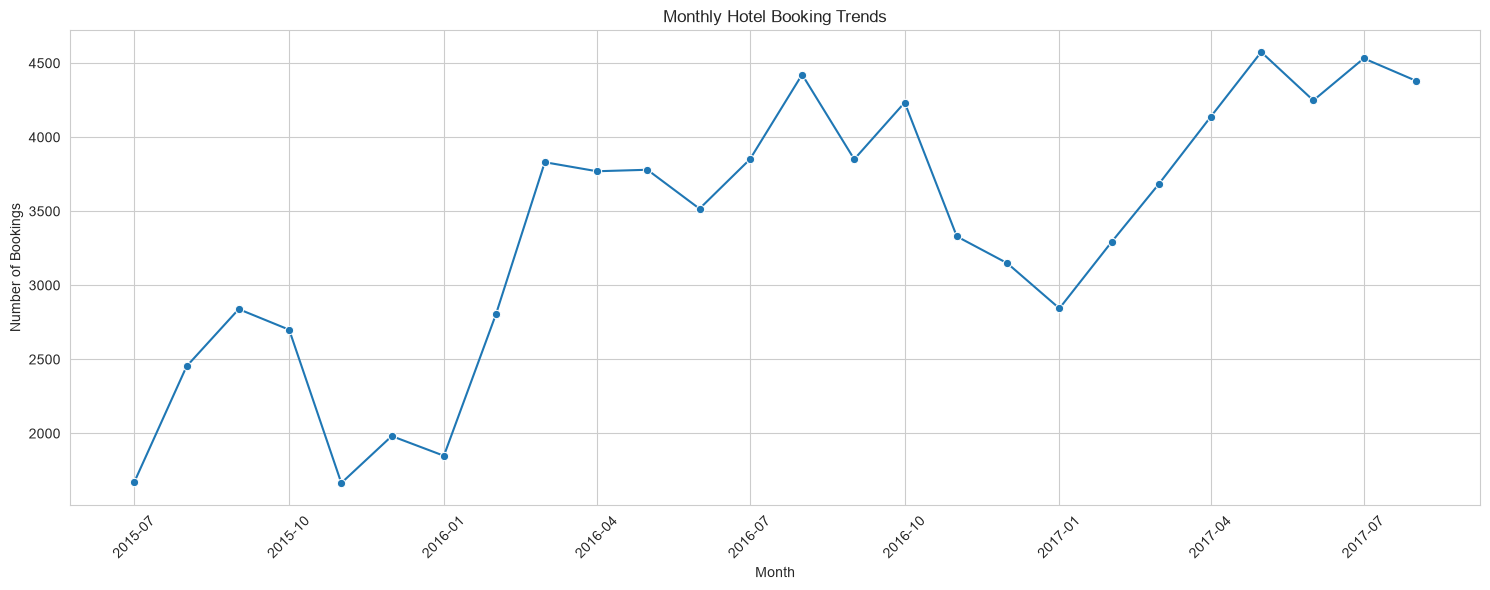

In [73]:

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_bookings,
    x="year_month",
    y="total_bookings",
    marker="o"
)

plt.title("Monthly Hotel Booking Trends")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/monthly_booking_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



1. Monthly Hotel Booking Trends

The first line chart tracks the total volume of monthly hotel bookings over a multi-year period stretching from mid-2015 to mid-2017.

Key Observations

• Overall Growth Trajectory: The dataset showcases a strong macro-upward trend. Total bookings started around 2,500 in mid-2015 and surged to peaks well above 4,500 by mid-2017.
• Cyclical Seasonality: Clear seasonal patterns emerge with bookings consistently plunging during the winter months (dipping near or below 2,500 around January 2016 and January 2017) and peaking during warmer summer intervals.
• Peak Booking Windows: Major volume surges occurred during late summer 2016 and reached their highest historical levels around May/July 2017.

In [74]:

monthly_cancellations = (
    df_clean.groupby("year_month")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

monthly_cancellations["cancellation_rate"] = (
    monthly_cancellations["canceled_bookings"] /
    monthly_cancellations["total_bookings"] * 100
)

monthly_cancellations.head()


,year_month,total_bookings,canceled_bookings,cancellation_rate
0,2015-07,1674,512,30.585424
1,2015-08,2453,571,23.277619
2,2015-09,2839,566,19.936597
3,2015-10,2700,440,16.296296
4,2015-11,1665,243,14.594595


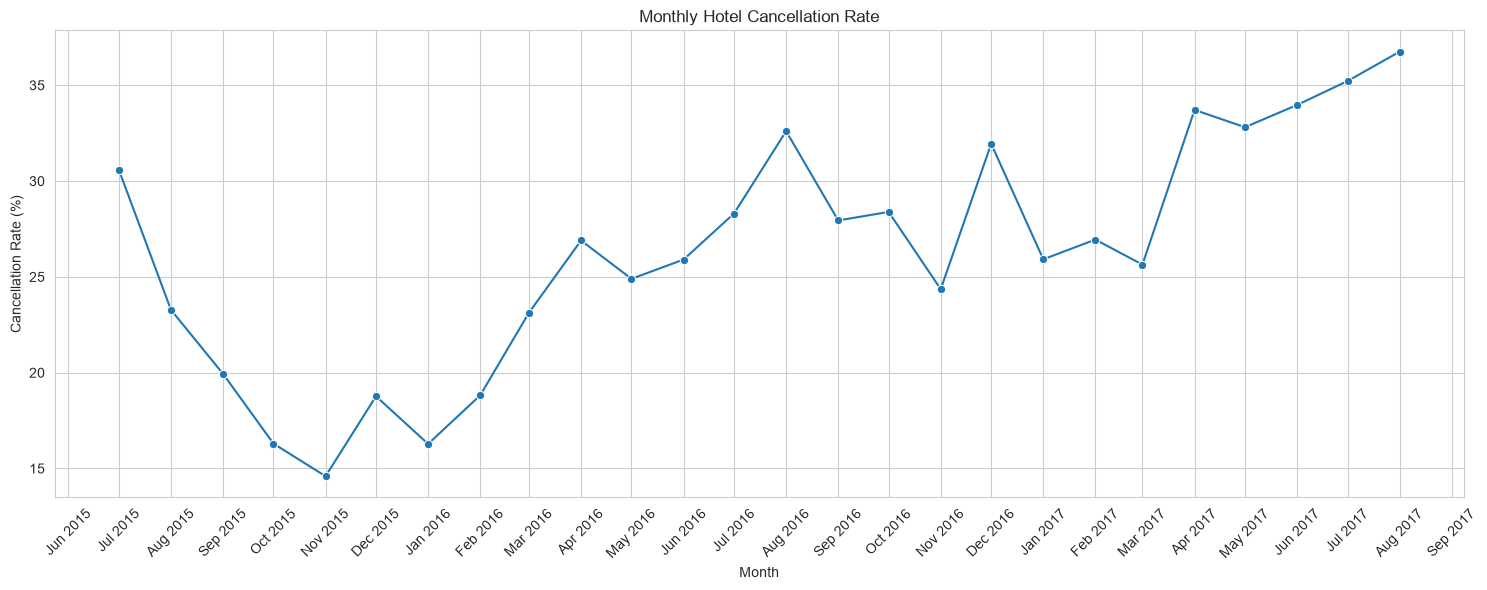

In [75]:
import matplotlib.dates as mdates

# Ensure year_month is a proper timestamp
if hasattr(monthly_cancellations["year_month"].dt, "to_timestamp"):
    monthly_cancellations["year_month"] = monthly_cancellations["year_month"].dt.to_timestamp()

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_cancellations,
    x="year_month",
    y="cancellation_rate",
    marker="o"
)

# Format x-axis ticks to show Month Name and Year (e.g., Jul 2015)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.title("Monthly Hotel Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/monthly_cancellation_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Monthly Hotel Cancellation Rate Analysis

* Overall Upward Trend: After dropping during the second half of 2015, the monthly cancellation rate climbed steadily from ~14.6% in November 2015 to a peak of ~36.8% in August 2017.
* Lowest Cancellation Period: Late autumn and early winter consistently saw the lowest cancellation rates—hitting an all-time low in November 2015 (~14.6%) and dipping again in January 2016 (~16.3%) and November 2016 (~24.4%).
* Peak Cancellation Spikes: Cancellations surged during peak summer months (August 2016 at ~32.6% and July–August 2017 at ~35.2%–36.8%) as well as a notable year-end spike in December 2016 (~31.9%).
* Key Business Takeaway: Cancellations have grown not only in raw volume alongside total bookings, but also as a higher percentage of overall reservations year over year—rising from 30.6% in July 2015 to 35.2% in July 2017.


## 13. Group-by Analysis

Group-by analysis helps us compare booking patterns across
different categorical variables.

In this section, we analyze booking volumes and cancellation
rates across hotel types, market segments, customer types,
and distribution channels.

In [76]:

# Booking count by hotel type

hotel_bookings = (
    df_clean.groupby("hotel")
    .size()
    .reset_index(name="total_bookings")
    .sort_values("total_bookings", ascending=False)
)

hotel_bookings


,hotel,total_bookings
0,City Hotel,53428
1,Resort Hotel,33968


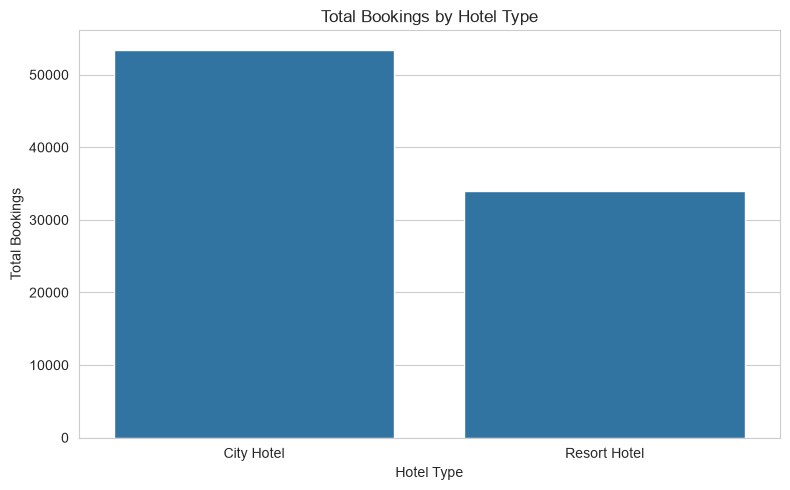

In [77]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=hotel_bookings,
    x="hotel",
    y="total_bookings"
)

plt.title("Total Bookings by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Total Bookings")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/bookings_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [78]:

market_cancellation = (
    df_clean.groupby("market_segment")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

market_cancellation["cancellation_rate"] = (
    market_cancellation["canceled_bookings"] /
    market_cancellation["total_bookings"] * 100
)

market_cancellation = market_cancellation.sort_values(
    "cancellation_rate",
    ascending=False
)

market_cancellation


,market_segment,total_bookings,canceled_bookings,cancellation_rate
7,Undefined,2,2,100.000000
6,Online TA,51618,18245,35.346197
4,Groups,4942,1335,27.013355
0,Aviation,227,45,19.823789
5,Offline TA/TO,13889,2063,14.853481
3,Direct,11804,1737,14.715351
1,Complementary,702,88,12.535613
2,Corporate,4212,510,12.108262



## Key Observations

• The Online TA Risk: Online Travel Agencies represent the single biggest segment by a massive margin (51,618 bookings). However, they also suffer from a highly severe cancellation rate of 35.35%. Over a third of your main revenue pipeline falls through.
• Groups and Volatility: Group bookings show the second highest structured cancellation rate at 27.01%. When groups cancel, it leaves large blocks of rooms empty simultaneously, creating a distinct revenue management risk.
• Stable Channels: Direct bookings and Corporate accounts demonstrate excellent stability, maintaining low cancellation rates between 12% and 15%.

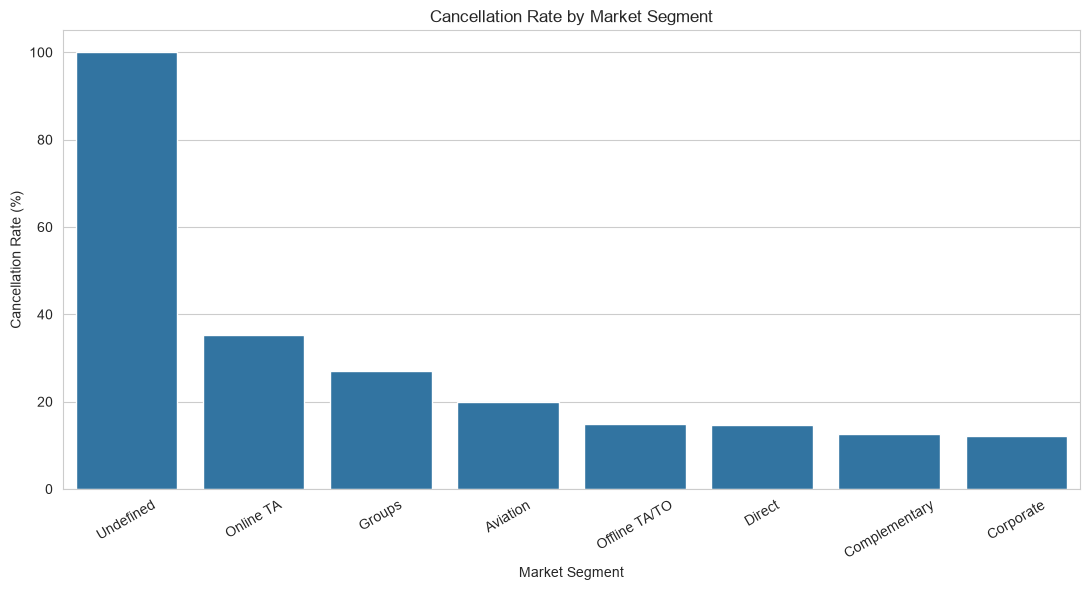

In [79]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=market_cancellation,
    x="market_segment",
    y="cancellation_rate"
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/cancellation_by_market_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [80]:

customer_analysis = (
    df_clean.groupby("customer_type")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

customer_analysis["cancellation_rate"] = (
    customer_analysis["canceled_bookings"] /
    customer_analysis["total_bookings"] * 100
)

customer_analysis.sort_values(
    "total_bookings",
    ascending=False
)


,customer_type,total_bookings,canceled_bookings,cancellation_rate
2,Transient,71986,21672,30.105854
3,Transient-Party,11727,1787,15.238339
0,Contract,3139,512,16.310927
1,Group,544,54,9.926471



## Key Observations

• Transient Dominance: Standard "Transient" customers (independent, individual travelers) make up the overwhelming majority of your customer base (71,986 bookings). They also cancel at a high rate of 30.11%.
• Transient-Party vs. Transient: Interestingly, when transient customers book as part of a package or party (Transient-Party), their cancellation rate drops by half down to 15.24%, indicating significantly stronger commitment.

In [81]:

channel_analysis = (
    df_clean.groupby("distribution_channel")
    .agg(
        total_bookings=("is_canceled", "count"),
        canceled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

channel_analysis["cancellation_rate"] = (
    channel_analysis["canceled_bookings"] /
    channel_analysis["total_bookings"] * 100
)

channel_analysis.sort_values(
    "total_bookings",
    ascending=False
)


,distribution_channel,total_bookings,canceled_bookings,cancellation_rate
3,TA/TO,69141,21412,30.968600
1,Direct,12988,1925,14.821374
0,Corporate,5081,648,12.753395
2,GDS,181,36,19.889503
4,Undefined,5,4,80.000000



## Key Observations

• TA/TO Dependency: The hotel relies heavily on Third-Party intermediaries (TA/TO) for 69,141 bookings. This reliance introduces major volatility with a 30.97% cancellation rate, likely driven by easy "free cancellation" terms offered on modern booking apps.
• Direct Channel Value: Direct bookings are vastly superior in terms of reliability, holding steady at a low 14.82% cancellation rate.

##  14. Scatter Plot Analysis

Scatter plots help identify relationships, patterns, clusters,
and unusual observations between two numerical variables.

In this section, we explore relationships between booking
lead time, average daily rate, and length of stay.

## 14.1 Scatter plot: Lead time vs ADR

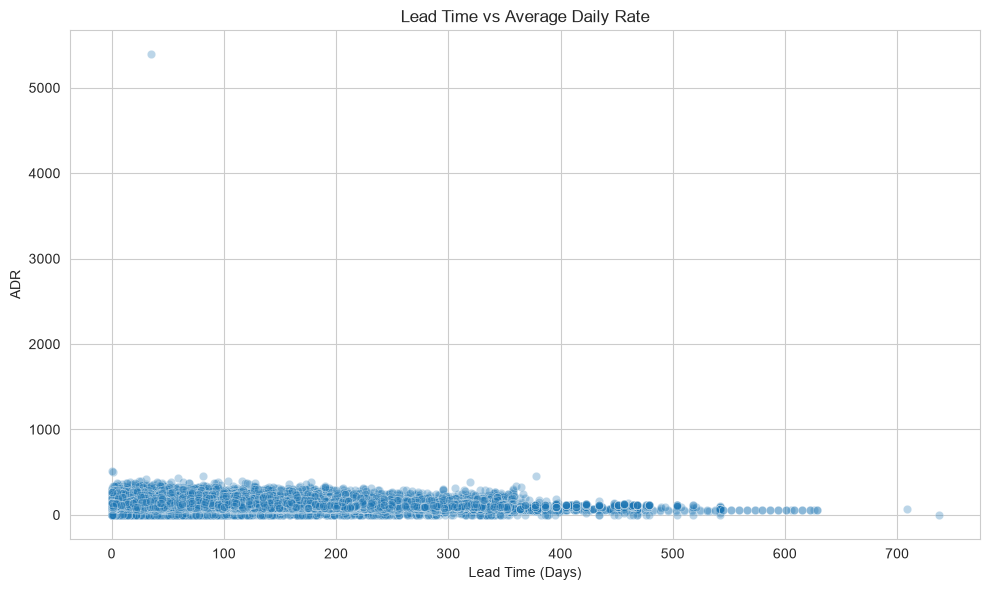

In [82]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="lead_time",
    y="adr",
    alpha=0.3
)

plt.title("Lead Time vs Average Daily Rate")
plt.xlabel("Lead Time (Days)")
plt.ylabel("ADR")

plt.tight_layout()

plt.savefig(
    "outputs/charts/lead_time_vs_adr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation 

1. Lead Time vs ADR

The scatter plot shows that ADR values are widely distributed across different lead times. There is no clear pattern indicating that bookings made earlier have higher or lower daily rates. This suggests that booking lead time does not have a noticeable relationship with the average daily rate.



## 14.2 Scatter plot: Weeknight stays vs ADR

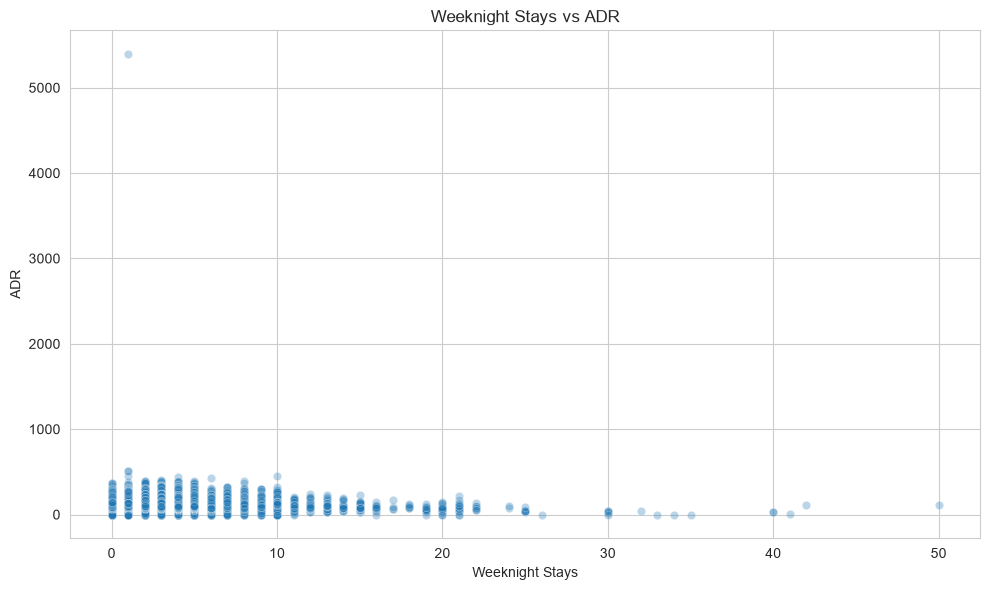

In [83]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="stays_in_week_nights",
    y="adr",
    alpha=0.3
)

plt.title("Weeknight Stays vs ADR")
plt.xlabel("Weeknight Stays")
plt.ylabel("ADR")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/weeknight_stays_vs_adr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation 
2. Weeknight Stays vs ADR

The scatter plot shows that ADR varies across different weekday stay durations. However, there is no strong visible pattern between the number of weeknight stays and ADR. This indicates that guests staying for more weekdays do not necessarily pay higher daily rates.

## 14.3 Scatter plot: Weekend stays vs Weeknight stays

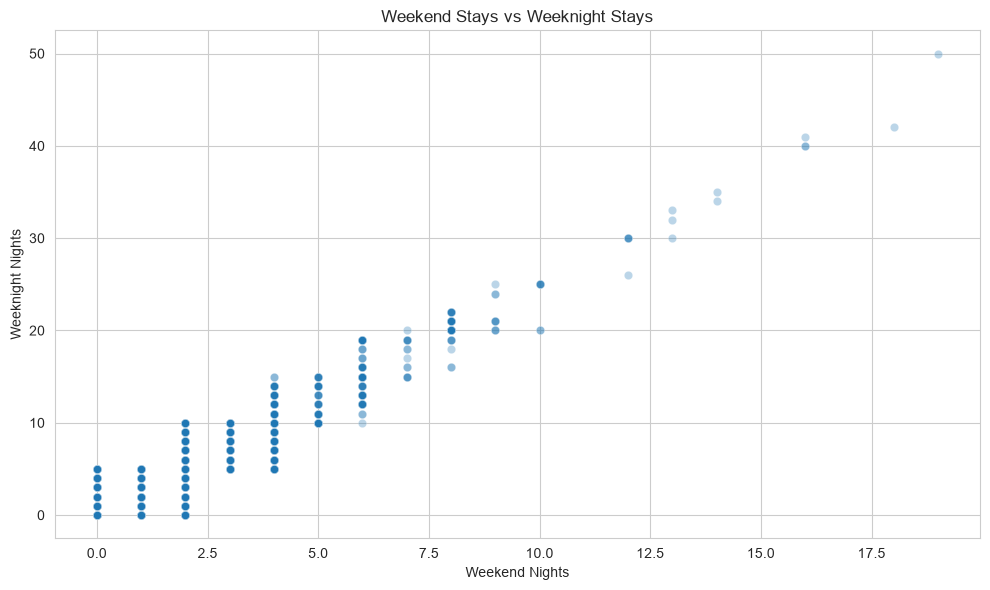

In [84]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="stays_in_weekend_nights",
    y="stays_in_week_nights",
    alpha=0.3
)

plt.title("Weekend Stays vs Weeknight Stays")
plt.xlabel("Weekend Nights")
plt.ylabel("Weeknight Nights")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/weekend_vs_weeknight_stays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation

3. Weekend Stays vs Weeknight Stays

The scatter plot shows a positive relationship between weekend and weeknight stays. Guests who stay for more weekend nights generally also tend to stay for more weeknights. Most bookings are concentrated around shorter stay durations, with fewer bookings involving longer stays.

## Key Findings and Data-Driven Insights

### 1. Guest Stay Duration
The analysis found a moderate positive relationship between weeknight stays and weekend stays (approximately 0.56). Guests who stay for more weekend nights generally tend to stay for more weeknights as well.

**Business Recommendation:** Hotels can use guest stay-duration patterns to improve room availability, staffing, and resource allocation.

### 2. Booking Lead Time and Cancellation
The correlation between lead time and cancellations was approximately 0.18, indicating a weak positive relationship. This suggests that bookings made further in advance are slightly more likely to be associated with cancellations.

**Business Recommendation:** Hotels can monitor bookings with longer lead times and consider sending booking reminders or offering suitable confirmation policies to reduce cancellation risks.

### 3. Differences in Potential Outliers Between Hotels
City Hotels had higher potential outlier percentages than Resort Hotels for lead time (3.18% vs. 1.78%), ADR (4.66% vs. 2.22%), and weeknight stays (1.29% vs. 0.53%). Resort Hotels had a slightly higher percentage of weekend-stay outliers (0.41% vs. 0.15%).

**Business Recommendation:** Hotels should monitor unusual booking durations, lead times, and room rates separately for each hotel type to identify unusual booking patterns and maintain data quality.

### 4. Relationship Between ADR and Booking Behaviour
The scatter plots showed no clear relationship between ADR and lead time or between ADR and weekday stay duration.

**Business Recommendation:** Hotels should consider additional factors, such as customer type, seasonality, and market segment, when reviewing room pricing strategies rather than relying only on booking lead time or stay duration.

### Overall Finding
The analysis highlights differences in guest booking behaviour, stay duration, and potential outliers between hotel types. These findings can help hotel management improve booking management, room allocation, pricing reviews, and operational planning.

## Conclusion and Business Recommendations

### Conclusion

The exploratory data analysis of the Hotel Booking Demand dataset provided useful insights into hotel booking patterns, customer behaviour, cancellation trends, room pricing, and stay durations.

The analysis revealed that City Hotels and Resort Hotels have differences in booking characteristics and potential outlier patterns. A moderate positive relationship was observed between weekend and weeknight stays, while ADR showed no clear relationship with lead time or weekday stay duration. The analysis also highlighted unusual ADR values that require further investigation.

Overall, the findings help understand customer booking behaviour and identify areas where hotel management can improve operational efficiency and decision-making.

### Business Recommendations

1. Improve Cancellation Management: Monitor cancellation rates across different market segments and distribution channels. Hotels can review booking confirmation processes and consider reminders for bookings made well in advance.

2. Optimize Room and Resource Allocation: Use monthly booking trends and guest stay-duration patterns to plan room availability, housekeeping schedules, and staff requirements more effectively.

3. Review Pricing Strategies: Analyze ADR across hotel types, customer segments, and seasons to identify opportunities for better pricing decisions. Avoid relying on lead time or stay duration alone when setting room rates.

4. Improve Data Quality: Investigate unusual ADR values, negative rates, and extreme booking durations before using the data for business reporting or pricing decisions.

5. Understand Customer Behaviour: Study booking patterns across customer types and distribution channels to develop targeted marketing strategies and improve the guest experience.

### Final Summary

This analysis demonstrates how exploratory data analysis can transform raw hotel booking data into meaningful business insights. By monitoring cancellations, understanding customer preferences, improving resource planning, and reviewing pricing patterns,